<a href="https://colab.research.google.com/github/lvi8544851094-eng/aiml-30-days/blob/main/Linear_regression_in_class_Rimt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

X = np.array([[1], [2], [3], [4], [5]], dtype=float)
y = np.array([35, 40, 50, 55, 65], dtype=float)

A = np.c_[np.ones(len(X)), X]
theta, residuals, rank, singular_values = np.linalg.lstsq(
    A, y, rcond=None
)

b, w = theta
print("Intercept:", b)
print("Slope:", w)
print("Predictions:", A @ theta)

Intercept: 26.499999999999975
Slope: 7.500000000000002
Predictions: [34.  41.5 49.  56.5 64. ]


### ———
### ① Introduction to Linear Regression & The Normal Equation (Analytical Approach)

#### What is Linear Regression?
Imagine you are trying to predict a student's final exam grade based on the number of hours they studied. If you plot this data on a graph, you will notice a trend: more study hours generally lead to higher marks.

**Linear Regression** is simply the process of finding the "best-fitting straight line" through these data points.

Mathematically, this line is represented by the formula:
$$y = w \cdot X + b$$
Where:
* **$y$** is the prediction (the final mark).
* **$X$** is our input feature (hours studied).
* **$w$** is the **slope** (or weight). It tells us how much the grade increases for every extra hour studied.
* **$b$** is the **intercept** (or bias). It tells us what grade a student would get if they studied for 0 hours.

#### What is the "Normal Equation" (Least Squares)?
Instead of guessing the slope ($w$) and intercept ($b$), we can compute them directly using a mathematical shortcut called the **Normal Equation** (or ordinary least squares).

This method calculates the mathematically perfect line that minimizes the sum of squared differences (residuals) between our predictions and the actual data in a single step:
$$\theta = (A^T A)^{-1} A^T y$$

In the code cell above, `np.linalg.lstsq` solved this exact equation. It found:
* **Intercept ($b$) ≈ 26.5**: Starting grade with 0 study hours.
* **Slope ($w$) = 7.5**: Every hour of study increases the grade by 7.5 points.

Learned slope: 7.713092604383466
Learned intercept: 25.73066808425846
Final cost: 0.8040480728748645


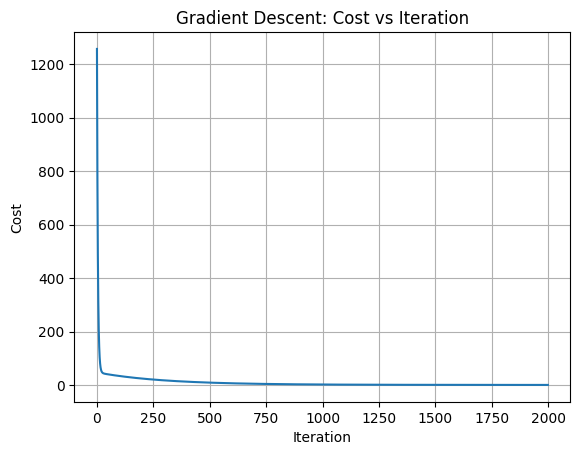

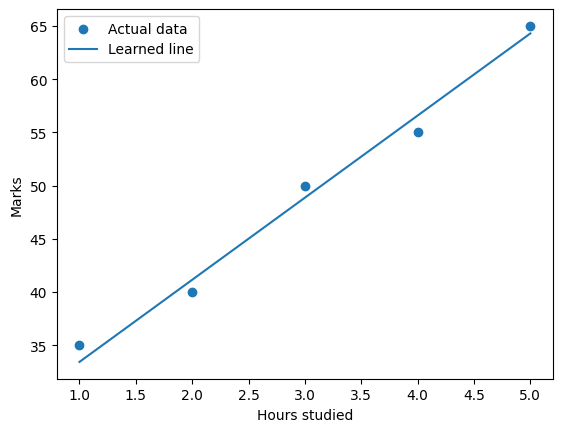

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Dataset: hours studied and marks
X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([35, 40, 50, 55, 65], dtype=float)

# Initialize parameters
w = 0.0
b = 0.0
alpha = 0.01
m = len(X)

cost_history = []

for iteration in range(2000):
    # 1. Predict using current parameters
    y_pred = w * X + b

    # 2. Calculate errors and cost
    error = y_pred - y
    cost = np.sum(error ** 2) / (2 * m)
    cost_history.append(cost)

    # 3. Calculate gradients using old parameters
    dw = np.sum(error * X) / m
    db = np.sum(error) / m

    # 4. Update both parameters
    w = w - alpha * dw
    b = b - alpha * db

print("Learned slope:", w)
print("Learned intercept:", b)
print("Final cost:", cost_history[-1])

plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Gradient Descent: Cost vs Iteration")
plt.grid(True)
plt.show()

plt.scatter(X, y, label="Actual data")
plt.plot(X, w * X + b, label="Learned line")
plt.xlabel("Hours studied")
plt.ylabel("Marks")
plt.legend()
plt.show()


### ———
### ② Gradient Descent: The Step-by-Step Optimization

#### Why not always use the Normal Equation?
Calculating the perfect line mathematically in one step works beautifully for small datasets. But for millions of rows of data, calculating $(A^T A)^{-1}$ takes too much computer memory and time. Instead, we use an iterative approach called **Gradient Descent**.

#### The Analogy: Walking Down a Mountain
Imagine you are standing at the top of a foggy mountain (representing high error/cost) and want to find your way down to the lowest valley (representing the best possible line with minimum error). Since you cannot see the bottom, you feel the slope of the ground under your feet and take a small step in the direction that goes downwards. You repeat this until the ground becomes flat.

#### How it Works in the Code:
1. **The Cost Function (How bad are we?):** We measure our performance using the Mean Squared Error (MSE):
   $$J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} (y_{pred}^{(i)} - y^{(i)})^2$$
2. **Gradients (Which way is down?):** We calculate the direction of steepest ascent (the slope of the hill) using partial derivatives:
   $$\frac{\partial J}{\partial w} = \frac{1}{m} \sum (y_{pred} - y) \cdot X$$
   $$\frac{\partial J}{\partial b} = \frac{1}{m} \sum (y_{pred} - y)$$
3. **The Learning Rate ($\alpha$):** This is the size of our step. If it's too small, the process takes forever. If it's too large, we might overstep and miss the valley completely.
4. **Updating Parameters:** We step downhill by subtracting the gradient scaled by our learning rate:
   $$w = w - \alpha \cdot dw$$
   $$b = b - \alpha \cdot db$$

As seen in the plots above, the **Cost** drops rapidly in the first few iterations and eventually levels off as we reach the optimal valley.

In [3]:

import numpy as np

# Each row is one student.
# Columns: hours studied, practice tests completed
X = np.array([
    [1, 1],
    [2, 1],
    [3, 2],
    [4, 2],
    [5, 3]
], dtype=float)

y = np.array([35, 40, 50, 55, 65], dtype=float)

# Initialize two weights and one intercept
w = np.zeros(X.shape[1])
b = 0.0
alpha = 0.01
m = len(y)

for i in range(3000):
    # All predictions at once
    predictions = X @ w + b
    errors = predictions - y

    # Vectorized gradients
    dw = (X.T @ errors) / m
    db = np.mean(errors)

    w = w - alpha * dw
    b = b - alpha * db

print("Weights:", w)
print("Intercept:", b)
print("Predictions:", X @ w + b)


Weights: [4.45019183 6.19658142]
Intercept: 24.45693560400606
Predictions: [35.10370885 39.55390067 50.20067392 54.65086574 65.29763899]


### ———
### ③ Vectorization: Making Computers Do Math at Light Speed

#### The Problem with Loops
If you have multiple features (e.g., hours studied **and** practice tests completed) and millions of samples, computing predictions one-by-one using `for` loops in Python is extremely slow.

#### The Solution: Vectorization
**Vectorization** is the process of grouping our equations into matrices so we can compute everything in parallel. Modern computer processors (CPUs/GPUs) are optimized to perform matrix calculations almost instantly.

#### The Math Behind the Code:
Instead of writing a loop to calculate predictions for each individual student, we stack all students into a matrix $X$ and multiply it by our weights vector $w$:

$$\begin{bmatrix} 1 & 1 \\ 2 & 1 \\ 3 & 2 \\ 4 & 2 \\ 5 & 3 \end{bmatrix} \times \begin{bmatrix} w_1 \\ w_2 \end{bmatrix} + b = \begin{bmatrix} \text{Prediction}_1 \\ \text{Prediction}_2 \\ \text{Prediction}_3 \\ \text{Prediction}_4 \\ \text{Prediction}_5 \end{bmatrix}$$

In Python, this matrix multiplication is done instantly with a single operator: `X @ w + b`.

In [4]:

import numpy as np

X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([35, 40, 50, 55, 65], dtype=float)

# First column represents the intercept
A = np.column_stack([np.ones(len(X)), X])

# Least-squares solution: intercept followed by slope
theta, *_ = np.linalg.lstsq(A, y, rcond=None)

b, w = theta

print("Intercept:", b)
print("Slope:", w)
print("Predictions:", A @ theta)
print("Mean squared error:", np.mean((A @ theta - y) ** 2))


Intercept: 26.499999999999975
Slope: 7.500000000000002
Predictions: [34.  41.5 49.  56.5 64. ]
Mean squared error: 1.4999999999999987


### ———
### ④ The Normal Equation vs. Gradient Descent

#### What is the Normal Equation?
Instead of taking thousands of small steps downhill using **Gradient Descent**, we can use an analytical formula to jump directly to the perfect weights. This mathematical shortcut is called the **Normal Equation**:

$$\theta = (A^T A)^{-1} A^T y$$

Where:
* **$\theta$** is the vector containing our optimal parameters (the intercept $b$ and slope $w$).
* **$A$** is our input feature matrix (with an extra column of $1$s added to represent the intercept).
* **$y$** is the actual target values vector.

#### How does it relate to the code above?
In the code cell above, we implemented this exact approach:
1. **`A = np.column_stack([np.ones(len(X)), X])`**: We created the matrix $A$ by gluing a column of ones to our features $X$. This accounts for the intercept ($b$).
2. **`np.linalg.lstsq(A, y, rcond=None)`**: This built-in NumPy function solves the Normal Equation under the hood. It computes the mathematical "least-squares" projection of $y$ onto the space spanned by $A$ in a single, rapid matrix calculation.

#### Pros and Cons of this Approach
* **Pros:**
  * No need to choose a learning rate ($\alpha$).
  * No need to run thousands of iterations (loops).
  * It gives the absolute, mathematically exact global minimum.
* **Cons:**
  * Calculating $(A^T A)^{-1}$ is incredibly expensive if you have a massive number of features (e.g., $10,000$ or more). It can slow down your computer or run out of memory. If that happens, **Gradient Descent** becomes the preferred choice!

Degree 1: Test MSE = 970.69
Degree 2: Test MSE = 10.73
Degree 5: Test MSE = 31.01


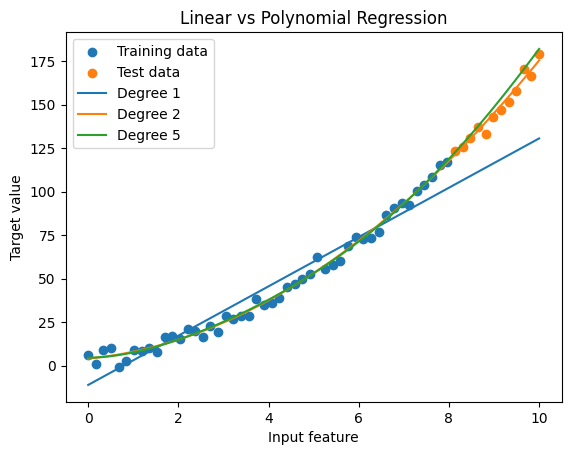

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Synthetic curved relationship
rng = np.random.default_rng(42)
X = np.linspace(0, 10, 60).reshape(-1, 1)
y = 5 + 2 * X.ravel() + 1.5 * X.ravel()**2
y = y + rng.normal(0, 4, size=len(y))

# Hold out the last 12 points for a simple test
X_train, X_test = X[:-12], X[-12:]
y_train, y_test = y[:-12], y[-12:]

degrees = [1, 2, 5]

plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_test, y_test, label="Test data")

x_plot = np.linspace(0, 10, 200).reshape(-1, 1)

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"Degree {degree}:",
        "Test MSE =", round(mean_squared_error(y_test, pred), 2)
    )

    plt.plot(
        x_plot,
        model.predict(x_plot),
        label=f"Degree {degree}"
    )

plt.xlabel("Input feature")
plt.ylabel("Target value")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()


### ———
### ④ Polynomial Regression: Fitting Curved Relationships

#### What if the relationship isn't a straight line?
In real life, data is rarely perfectly linear. For instance, maybe studying a little bit helps a bit, but studying a lot helps exponentially more. A straight line (Degree 1) will fail to capture this curvature.

#### How Polynomial Regression Works:
We don't actually need a new algorithm! We still use standard Linear Regression, but we mathematically warp our input features to create curves.

* **Degree 1:** $y = w_1 X + b$ (A straight line)
* **Degree 2:** $y = w_1 X + w_2 X^2 + b$ (A smooth parabola/curve)
* **Degree 5:** $y = w_1 X + w_2 X^2 + w_3 X^3 + w_4 X^4 + w_5 X^5 + b$ (A highly flexible, squiggly line)

#### The Danger of Overfitting:
Looking at the graph above:
* **Degree 1 (Underfitting):** Too simple. It misses the curve entirely and has a massive Test Error (MSE ≈ 970).
* **Degree 2 (Just Right):** Captures the natural curve beautifully and generalizes well to new, unseen test data (MSE ≈ 10).
* **Degree 5 (Overfitting):** The model is too flexible. It tries so hard to pass through every single training point that it learns the random noise instead of the real trend, causing its performance on new test data to get worse (MSE ≈ 31).